In [1]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

In [2]:
arxiv_wrapper=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=arxiv_wrapper)
print(arxiv.name)

arxiv


In [3]:
arxiv.invoke("Attention is all you need")

AttributeError: 'Search' object has no attribute 'results'

In [4]:
wikipedia_wrapper=WikipediaAPIWrapper(top_k_results=2,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=wikipedia_wrapper)
wiki.name

'wikipedia'

In [5]:
wiki.invoke("What is machine learning")

'Page: Machine learning\nSummary: Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.\nStatistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.\nFrom '

In [10]:
from dotenv import load_dotenv
import os
load_dotenv()

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["OLLAMA_API_KEY"]=os.getenv("OLLAMA_API_KEY")
os.environ["LANGCHAIN_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGCHAIN_TRACING_V2"]="true"

os.environ["LANGCHAIN_PROJECT"]="React_Agent"

In [7]:
!ollama pull deepseek-v2

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕██████████████████▏   32 B                         
pulling 2b2c35718a16: 100% ▕██████████████████▏  494 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                

In [11]:
## Custom Funtions
def multiply(a:int,b:int)->int:
    """Multiply a and b
    Args:
        a:First int
        b:Second int
    """
    return a * b

def add (a:int,b:int)->int:
    """Adds a and b
    Args:
        a:First int
        b:Second int
    """
    return a + b
def divide (a:int,b:int)->int:
    """Divide a and b
    Args:
        a:First int
        b:Second int
    """
    return a // b

tools=[wiki,add,multiply,divide]

In [12]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily=TavilySearchResults()

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_28948\3543858584.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily=TavilySearchResults()


In [14]:
tavily.invoke("provide me the recent news on NVIDIA for November 14")

[{'title': 'Nvidia fallout so far: From allegations to Huang’s resignation',
  'url': 'https://www.youtube.com/watch?v=U5KKq3rNE68',
  'content': "# Nvidia fallout so far: From allegations to Huang’s resignation\n## Channel: CNN (verified)\n20.1M subscribers\n73 likes\n\n### Description\n6,068 views\nPosted: 2026-11-14\nJensen Huang, the founder who propelled Nvidia to become one of the world’s most valuable companies, has resigned from his role as chief executive after 33 years. The announcement from Nvidia’s board Thursday morning ends a whirlwind several days of speculation about Huang’s future in the wake of a stunning corporate scandal.\n\nCNN looks at the big developments of the saga this week. [...] CNN looks at the big developments of the saga this week.\n\n0:00 Nvidia announces investigation into Jensen Huang (November 9)\n1:14 Tech expert on scandal: “What a mess” (November 9)\n4:59 What Trump knew about the scandal (November 10)\n6:55 Second affair revealed & who is Alice Hu

In [31]:
tools=[wiki,tavily,add,divide,multiply]

In [16]:
from langchain_groq import ChatGroq
llm=ChatGroq(model="qwen/qwen3.8-27b")
llm_with_tools=llm.bind_tools(tools)

In [18]:
from pprint import pprint
from langchain_core.messages import AIMessage,HumanMessage
pprint(llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]))

AIMessage(content="Here are some of the most significant AI news stories from the last few days (as of late May 2024):\n\n### 1. **Unveiling of GPT-4o**\nOpenAI introduced a new flagship model called **GPT-4o**. This is an update to GPT-4 Turbo, designed to be better, faster, and more cost-effective. It's also more capable of following complex instructions and generating high-quality code. GPT-4o is available in ChatGPT, the API, and Microsoft Copilot.\n\n### 2. **Google's New Gemini 1.5 Pro Model**\nGoogle DeepMind released **Gemini 1.5 Pro**, their most advanced multimodal AI model. It's designed to work with text, images, audio, and video. A key feature is its ability to process **very long context windows** (up to 1 million tokens), which is a significant improvement over previous models. This allows it to analyze large amounts of data, like entire codebases or long videos, in a single prompt.\n\n### 3. **Microsoft's AI-Powered Copilot for Windows**\nMicrosoft announced a major upd

In [19]:
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls

[{'name': 'tavily_search_results_json',
  'args': {'query': 'latest AI news this week'},
  'id': 'rnz9y7s7g',
  'type': 'tool_call'},
 {'name': 'tavily_search_results_json',
  'args': {'query': 'OpenAI Anthropic Google DeepMind announcement'},
  'id': 'avk6rpbjz',
  'type': 'tool_call'}]

In [20]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

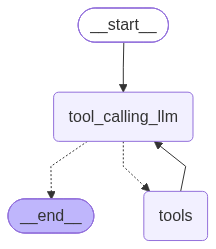

In [21]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [23]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for MArch 3rd 2025,add 5 plus 5 and then multiply by 10
================================== Ai Message ==================================

I'll help you with both tasks. Let me search for recent AI news from March 3rd, 2025, and perform the calculation.
Tool Calls:
  tavily_search_results_json (1gqt118b7)
 Call ID: 1gqt118b7
  Args:
    query: top AI news March 3 2025
  add (769zhdd43)
 Call ID: 769zhdd43
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "Top 10 AI Developments in the Past Week [Week 1 - March 2025 ] - Datahub Analytics", "url": "https://datahubanalytics.com/top-10-ai-developments-in-the-past-week-week-1-march-2025", "content": "New York City’s Metropolitan Transportation Authority (MTA) is working with Google to enhance subway maintenance by deploying 

In [24]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================

Machine learning is a field of artificial intelligence (AI) that focuses on building systems that can learn from data to make predictions or decisions without being explicitly programmed for each task.

Here's a breakdown of the key concepts:

### Core Idea
Instead of writing explicit rules (like "if X, then Y"), you feed the computer large amounts of data and examples. The computer then identifies patterns and relationships within that data to build a model that can generalize to new, unseen data.

### How It Works (Simplified)
1. **Data**: You provide a dataset (e.g., thousands of labeled images of cats and dogs).
2. **Model**: You choose an algorithm (e.g., a neural network) that can adjust its internal parameters.
3. **Training**: The algorithm iteratively adjusts its parameters to minimize the e

## Agent Memory

#### MemorySaver
LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer gives us memory, allowing LangGraph to pick up from the last state update.

One of the easiest checkpointers to use is the MemorySaver, an in-memory key-value store for Graph state.

All we need to do is simply compile the graph with a checkpointer, and our graph has memory!



In [32]:
from langchain_google_genai import ChatGoogleGenerativeAI
llm=ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")
llm_with_tools=llm.bind_tools(tools)

In [33]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [34]:
def tool_calling_llm(state:State):
    return{"messages":[llm_with_tools.invoke(state["messages"])]}
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")

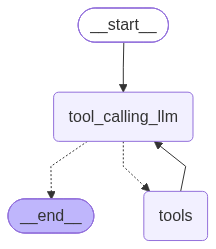

In [35]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
graph_memory=builder.compile(checkpointer=memory)
#view
display(Image(graph_memory.get_graph().draw_mermaid_png()))

In [36]:
config={"configurable":{"thread_id":"1"}}
# Specify an input
messages = [HumanMessage(content="Add 12 and 13.")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_10071529466880889695)
 Call ID: call_10071529466880889695
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EnMKcQFpFH0T11pfbrBNquQotO8p8/PZOk7Z9uAy3zLeD2yVbxNKHpKC3uyufB5fNsAUg0QTp5AqntRq3ygDj6mTYehiSz6HU0n8cUk45IOLvDajw+5FV3b3C8p9RelKDPxm5iv6ZY9SHKv/BYepbl4ppTL9'}}]


In [37]:
messages = [HumanMessage(content="add that number to 25")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_10071529466880889695)
 Call ID: call_10071529466880889695
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EnMKcQFpFH0T11pfbrBNquQotO8p8/PZOk7Z9uAy3zLeD2yVbxNKHpKC3uyufB5fNsAUg0QTp5AqntRq3ygDj6mTYehiSz6HU0n8cUk45IOLvDajw+5FV3b3C8p9RelKDPxm5iv6ZY9SHKv/BYepbl4ppTL9'}}]
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_15552056117929385156)
 Call ID: call_15552056117929385156
  Args:
    a: 25
    b: 25
====

In [38]:
messages = [HumanMessage(content="then multiplty that number by 2")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_10071529466880889695)
 Call ID: call_10071529466880889695
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EnMKcQFpFH0T11pfbrBNquQotO8p8/PZOk7Z9uAy3zLeD2yVbxNKHpKC3uyufB5fNsAUg0QTp5AqntRq3ygDj6mTYehiSz6HU0n8cUk45IOLvDajw+5FV3b3C8p9RelKDPxm5iv6ZY9SHKv/BYepbl4ppTL9'}}]
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_15552056117929385156)
 Call ID: call_15552056117929385156
  Args:
    a: 25
    b: 25
====